# **Experiment Notebook**



In [173]:
# Do not modify this code
!pip install -q utstd

from utstd.ipyrenders import *

In [174]:
# Do not modify this code
import warnings
warnings.simplefilter(action='ignore')

In [175]:
import pandas as pd

pd.__version__

'2.2.2'

---
## Student Information

In [176]:
student_name = "Viet Hoang Pham"
student_id = "25935901"
group_id = "30"

In [177]:
# Do not modify this code
print_tile(size="h1", key='student_name', value=student_name)

In [178]:
# Do not modify this code
print_tile(size="h1", key='student_id', value=student_id)

In [179]:
# Do not modify this code
print_tile(size="h1", key='group_id', value=group_id)

---
## 0. Python Packages

In [180]:
import pandas as pd
import numpy as np
import requests
from pathlib import Path
import re
import matplotlib.pyplot as plt
import seaborn as sns

from mykrml_25935901.explore.summary import missing_summary, cardinality_summary, duplicate_report

---
## A. Project Description

In [181]:
business_use_case_description = """
The goal is to give cryptocurrency investors a single Asset Performance Index (0-100) that forecasts how well a chosen coin is likely to perform 7 days ahead. The score combines recent returns, trend strength, trading volume and price stability. An XGBoost model predicts it, and a FastAPI service delivers it to a Streamlit web app along with feature importance, so users can see what drives each score. For the business, this turns complex, fast-moving market data into a clear and explainable signal. It helps investors compare assets and support their own decisions, without replacing their judgement or acting as financial advice.
"""

In [182]:
# Do not modify this code
print_tile(size="h3", key='business_use_case_description', value=business_use_case_description)

In [280]:
business_objectives = """
Accurate Asset Performance Index forecasts would help investors spot coins likely to strengthen or weaken over the next 7 days. They could time entries and exits better, compare assets quickly and build trust in the platform. Incorrect forecasts could do the opposite. Overestimating performance might push investors into buying a weakening asset and taking losses. Underestimating it could make them miss genuine opportunities. Repeated errors would erode user trust, harm the platform’s reputation and create possible regulatory or ethical exposure if users treat the score as financial advice. Crypto markets are highly volatile, so even a well-performing model will sometimes be wrong. That is why the platform should show the score with its uncertainty and feature drivers, and present it as decision support rather than a guarantee.
Hypothesis: A tuned XGBoost regressor will forecast the Asset Performance Index 7 days ahead more accurately than the naive
persistence baseline ("next week's API = today's API"). Success is defined as at least a 10% reduction in MAE against the naive baseline on the unseen 2024-2025 test set.
"""

In [281]:
# Do not modify this code
print_tile(size="h3", key='business_objectives', value=business_objectives)

In [185]:
stakeholders_expectations_explanations = """
The predicted Asset Performance Index is shown in the Streamlit web app as a 7-day-ahead performance score with feature importance. It is also exposed through a FastAPI service that other prediction services and the frontend consume over HTTP. The direct users are cryptocurrency investors and traders, who use the score to compare coins, check an asset’s short-term outlook and support buy, hold or sell decisions. Other impacted parties include: the platform operator, whose credibility depends on accuracy; teammates’ models and pages that rely on the shared return features; people affected indirectly by investors’ decisions, such as their families or anyone whose money they manage. Less experienced retail investors are the most vulnerable group if they over-trust the score. That is why it should be presented clearly as decision support, not financial advice.
"""

In [186]:
# Do not modify this code
print_tile(size="h3", key='stakeholders_expectations_explanations', value=stakeholders_expectations_explanations)

---
## C. Data Understanding

### C.1   Load Raw Data


In [187]:
RAW_DIR = Path("../data/raw")

frames = []
for csv_path in sorted(RAW_DIR.glob("*/*.csv")):
    if csv_path.stat().st_size < 10:  # skip empty files (only a BOM)
        continue
    df = pd.read_csv(csv_path, sep=";", encoding="utf-8-sig")
    df["coin"] = csv_path.parent.name.split("(")[-1].rstrip(")")
    frames.append(df)

raw_df = pd.concat(frames, ignore_index=True)

for col in ["timeOpen", "timeClose", "timeHigh", "timeLow", "timestamp"]:
    raw_df[col] = pd.to_datetime(raw_df[col], utc=True)

raw_df = (raw_df.drop_duplicates(subset=["coin", "timeOpen"])
                .sort_values(["coin", "timeOpen"])
                .reset_index(drop=True))

raw_df.head()

,timeOpen,timeClose,timeHigh,timeLow,name,open,high,low,close,volume,marketCap,timestamp,coin,circulatingSupply
0,2015-01-01 00:00:00+00:00,2015-01-01 23:59:59.999000+00:00,2015-01-01 00:04:00+00:00,2015-01-01 23:44:00+00:00,2781,320.434998,320.434998,314.002991,314.248993,8036550.0,4.297536e+09,2015-01-01 23:59:59.999000+00:00,BTC,NaN
1,2015-01-02 00:00:00+00:00,2015-01-02 23:59:59.999000+00:00,2015-01-02 20:19:01+00:00,2015-01-02 01:04:01+00:00,2781,314.079010,315.838989,313.565002,315.032013,7860650.0,4.309551e+09,2015-01-02 23:59:59.999000+00:00,BTC,NaN
2,2015-01-03 00:00:00+00:00,2015-01-03 23:59:59.999000+00:00,2015-01-03 00:24:01+00:00,2015-01-03 23:59:00+00:00,2781,314.846008,315.149994,281.082001,281.082001,33054400.0,3.846270e+09,2015-01-03 23:59:59.999000+00:00,BTC,NaN
3,2015-01-04 00:00:00+00:00,2015-01-04 23:59:59.999000+00:00,2015-01-04 10:14:01+00:00,2015-01-04 15:29:01+00:00,2781,281.145996,287.230011,257.612000,264.195007,55629100.0,3.616321e+09,2015-01-04 23:59:59.999000+00:00,BTC,NaN
4,2015-01-05 00:00:00+00:00,2015-01-05 23:59:59.999000+00:00,2015-01-05 08:54:00+00:00,2015-01-05 00:04:01+00:00,2781,265.084015,278.341003,265.084015,274.473999,43962800.0,3.758098e+09,2015-01-05 23:59:59.999000+00:00,BTC,NaN


In [188]:
# Missing data
def fill_daily_calendar(df):
    """Add a row for every calendar day per coin (NaN where data is missing),
    so rolling windows and shift(-7) count days, not rows."""
    out = []
    for coin, g in df.groupby("coin"):
        full = pd.date_range(g["timeOpen"].min(), g["timeOpen"].max(), freq="D")
        g = g.set_index("timeOpen").reindex(full)
        g["coin"] = coin
        out.append(g.rename_axis("timeOpen").reset_index())
    return pd.concat(out, ignore_index=True)

print("Rows before:", len(raw_df))
raw_df = fill_daily_calendar(raw_df)
print("Rows after: ", len(raw_df), "| missing days:", raw_df["close"].isna().sum())

Rows before: 28784
Rows after:  29116 | missing days: 332


In [189]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29116 entries, 0 to 29115
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype              
---  ------             --------------  -----              
 0   timeOpen           29116 non-null  datetime64[ns, UTC]
 1   timeClose          28784 non-null  datetime64[ns, UTC]
 2   timeHigh           28784 non-null  datetime64[ns, UTC]
 3   timeLow            28784 non-null  datetime64[ns, UTC]
 4   name               28784 non-null  float64            
 5   open               28784 non-null  float64            
 6   high               28784 non-null  float64            
 7   low                28784 non-null  float64            
 8   close              28784 non-null  float64            
 9   volume             28784 non-null  float64            
 10  marketCap          28784 non-null  float64            
 11  timestamp          28784 non-null  datetime64[ns, UTC]
 12  coin               29116 non-null  object     

In [190]:
raw_df.shape

(29116, 14)

In [191]:
# Check the duplicate
duplicate_report(raw_df, keys=['coin', 'timeOpen'])

DuplicateReport(keys=['coin', 'timeOpen'], n_rows=29116, n_exact_duplicate_rows=0, n_key_duplicate_rows=0, n_key_groups=0, varying_columns=Empty DataFrame
Columns: [n_groups_varying, pct_groups_varying]
Index: [])

### C.2 Define Target variable

In [192]:
HORIZON = 7

def add_api_target(df, horizon=HORIZON):
    df = df.sort_values(["coin", "timeOpen"]).copy()
    g = df.groupby("coin", group_keys=False)

    # Features (owned by A, B, C, D) - computed per coin, using data up to t only
    df["DailyReturn"]    = g["close"].pct_change(fill_method=None)
    df["Return20"]       = g["close"].pct_change(20, fill_method=None)
    ma5                  = g["close"].transform(lambda s: s.rolling(5).mean())
    ma20                 = g["close"].transform(lambda s: s.rolling(20).mean())
    df["TrendStrength"]  = ma5 / ma20 - 1
    vol_sma20            = g["volume"].transform(lambda s: s.rolling(20).mean())
    df["RelativeVolume"] = df["volume"] / vol_sma20
    df["Volatility20"]   = df.groupby("coin")["DailyReturn"].transform(lambda s: s.rolling(20).std())

    # Intermediate scores
    rs = ((df["Return20"] + 0.20) / 0.40).clip(0, 1)
    ts = ((df["TrendStrength"] + 0.10) / 0.20).clip(0, 1)
    rv = df["RelativeVolume"].clip(upper=2) / 2
    ps = 1 - df["Volatility20"]

    # API at time t, then shift so each row's label is the API 7 days later
    df["API"] = 100 * (0.40 * rs + 0.30 * ts + 0.20 * rv + 0.10 * ps)
    df["API_t+7"] = df.groupby("coin")["API"].shift(-horizon)
    return df

In [193]:
df = add_api_target(raw_df)
target_name = "API_t+7"
df = df.dropna(subset=["Return20", "TrendStrength", "RelativeVolume", "Volatility20", target_name])

In [194]:
target_definition_explanations = """
The Asset Performance Index is defined as a 0-100 score that blends four signals of healthy price behaviour, each scaled to 0-1 so they can be compared and combined:
Return Strength (40%) treats a 20-day return of −20% as 0 and +20% as 1, capped beyond that, because realised price gain matters most to investors.
Trend Strength (30%) rewards a short-term average (MA5) running above the longer-term one (MA20), which signals the move is sustained rather than a one-off spike.
Relative Volume (20%) rewards above-average trading activity (capped at 2× normal), which suggests broad market participation backs the move.
Price Stability (10%) penalises high volatility, so an asset rising smoothly scores higher than an erratic one.
Capping each component limits the influence of extreme crypto moves, and the weights rank return above confirmation and risk signals. The target is taken 7 days after the feature date (t+7), so the model learns to forecast next week’s performance from information available today. That matches the business use of forward-looking decision support and avoids data leakage.
"""

In [195]:
# Do not modify this code
print_tile(size="h3", key='target_definition_explanations', value=target_definition_explanations)

### C.3 Create Target variable

In [196]:
target_name = 'API_t+7'

### C.4 Explore Target variable

In [197]:
target = df[target_name]

count    28541.00
mean        55.43
std         23.65
min          9.82
25%         36.99
50%         53.92
75%         74.72
max         99.84
Name: API_t+7, dtype: float64 
skew: 0.1


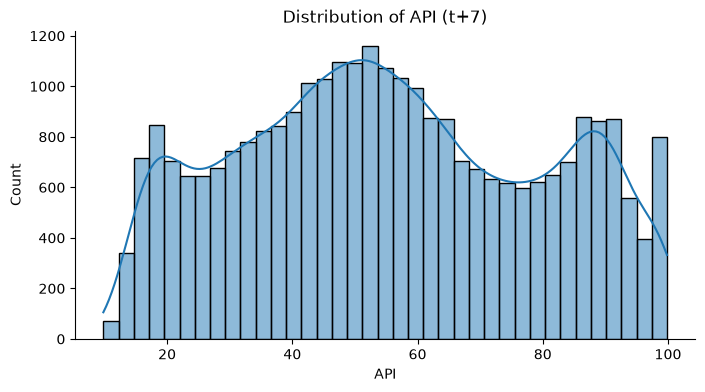

In [198]:
# Overall distribution
print(target.describe().round(2), "\nskew:", round(target.skew(), 2))
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(target, kde=True, ax=ax)
ax.set(title="Distribution of API (t+7)", xlabel="API", ylabel="Count")
sns.despine()
plt.show()

      mean   std   min   max
coin                        
BTC   58.7  20.7  14.1  99.8
DOGE  53.2  24.4  10.2  99.7
ETH   57.4  24.8  10.7  99.8
SOL   56.8  26.4  10.5  99.7
TRX   56.3  21.3   9.8  99.8
XLM   51.4  24.4  10.9  99.7
XMR   57.6  23.4  11.5  99.7
XRP   52.8  23.3  10.6  99.7


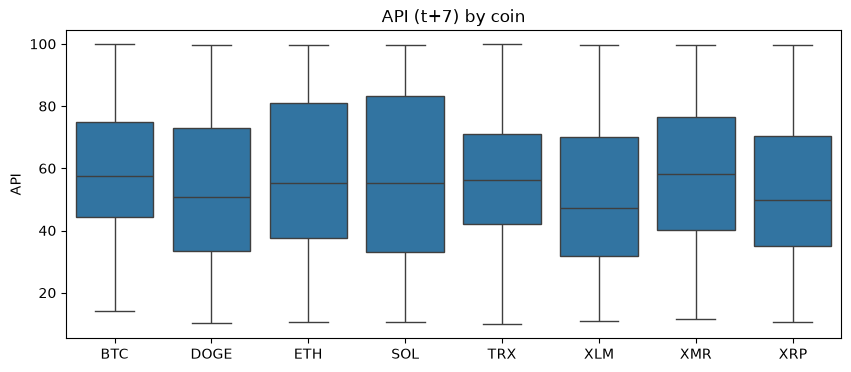

In [199]:
# Distribution per coin
print(df.groupby("coin")[target_name].agg(["mean", "std", "min", "max"]).round(1))
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=df, x="coin", y=target_name, ax=ax)
ax.set(title="API (t+7) by coin", xlabel="", ylabel="API")
plt.suptitle("")
plt.show()

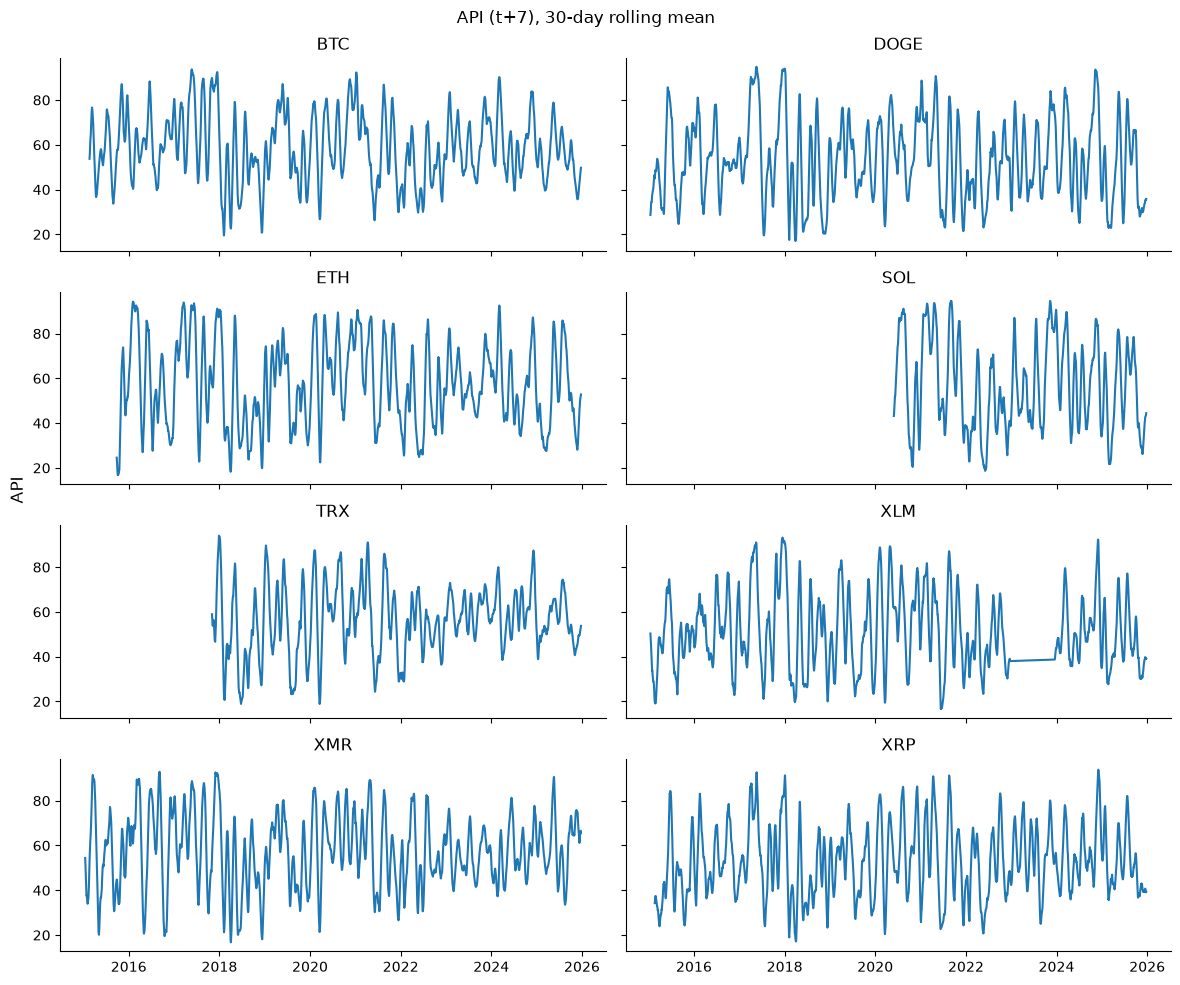

In [200]:
# Over time
coins = sorted(df["coin"].unique())
fig, axes = plt.subplots(4, 2, figsize=(12, 10), sharex=True, sharey=True)
for ax, coin in zip(axes.flat, coins):
    s = df[df["coin"] == coin].set_index("timeOpen")[target_name]
    ax.plot(s.rolling(30).mean())
    ax.set_title(coin)
fig.suptitle("API (t+7), 30-day rolling mean")
fig.supylabel("API")
plt.tight_layout()
sns.despine()
plt.show()

In [201]:
# How often each component hits its clip limit
rs = (df["Return20"] + 0.20) / 0.40
ts = (df["TrendStrength"] + 0.10) / 0.20
print(pd.DataFrame({
    "at 0": [(rs <= 0).mean(), (ts <= 0).mean(), None],
    "at 1": [(rs >= 1).mean(), (ts >= 1).mean(), (df["RelativeVolume"] >= 2).mean()],
}, index=["RS", "TS", "RV"]).round(3))

     at 0   at 1
RS  0.113  0.187
TS  0.098  0.136
RV    NaN  0.052


In [202]:
# Correlation with the 4 inputs and API today
print(df[["Return20", "TrendStrength", "RelativeVolume", "Volatility20", "API", target_name]].corr()[target_name].round(3))

Return20          0.288
TrendStrength     0.545
RelativeVolume    0.263
Volatility20      0.034
API               0.633
API_t+7           1.000
Name: API_t+7, dtype: float64


In [203]:
target_distribution_explanations = """
The distribution is broad and almost symmetric (skew 0.1). It is flatter than a normal curve, and a second bump appears at 80-100, so no transformation is needed and a squared-error loss is suitable. Coin-level means are close (51.4 for XLM to 58.7 for BTC) and every coin covers nearly the full range. This supports training one model on all coins, with coin optionally added as an input. The rolling-mean plots show the target moves with market cycles: it is low in bear periods such as 2018 and 2022 and high in bull runs such as 2017 and 2020-21. This means the data is not stationary, so train and test must be split by date with a 7-day gap rather than randomly. A key limitation comes from the formula itself. Return Strength is clipped at 0 or 1 in about 30% of rows and Trend Strength in about 23%, so the index stops changing in extreme markets, which explains the bump at the top of the range. In addition, Price Stability carries only 10% weight and volatility is usually small, so Volatility20 has almost no correlation with the target (0.03) and adds little signal. Among the inputs, TrendStrength is the strongest driver (r = 0.55), followed by Return20 (0.29) and RelativeVolume (0.26). Finally, today's API already correlates 0.63 with the API 7 days later, so "next week = today" is a strong baseline that the model must clearly beat to add value.
"""

In [204]:
# Do not modify this code
print_tile(size="h3", key='target_distribution_explanations', value=target_distribution_explanations)

### C.5 Explore Feature of Interest `Return20`

In [205]:
# Explore function
def explore(df, features, target=target_name, bins=10):
    """Summary stats, distributions and binned relationship with the target."""
    print(df[features].describe(percentiles=[.01, .5, .99]).T.round(4))
    print("\nCorrelation with target:\n", df[features + [target]].corr()[target].drop(target).round(3))

    fig, axes = plt.subplots(len(features), 2, figsize=(12, 4 * len(features)), squeeze=False)
    for i, f in enumerate(features):
        ax_hist, ax_bin = axes[i]

        lo, hi = df[f].quantile([.01, .99])
        sns.histplot(x=df[f].clip(lo, hi), bins=50, kde=True, ax=ax_hist)
        ax_hist.set(title=f"{f} (clipped 1-99%)", xlabel=f)

        deciles = pd.qcut(df[f], bins, labels=False, duplicates="drop") + 1
        sns.pointplot(x=deciles, y=df[target], errorbar=None, ax=ax_bin)
        ax_bin.set(title=f"Mean {target} by {f} decile", xlabel="decile", ylabel=target)
    sns.despine()
    plt.tight_layout()
    plt.show()

            count    mean     std     min      1%     50%     99%      max
Return20  28541.0  0.0925  0.6377 -0.7031 -0.4292  0.0006  1.7983  23.4762

Correlation with target:
 Return20    0.288
Name: API_t+7, dtype: float64


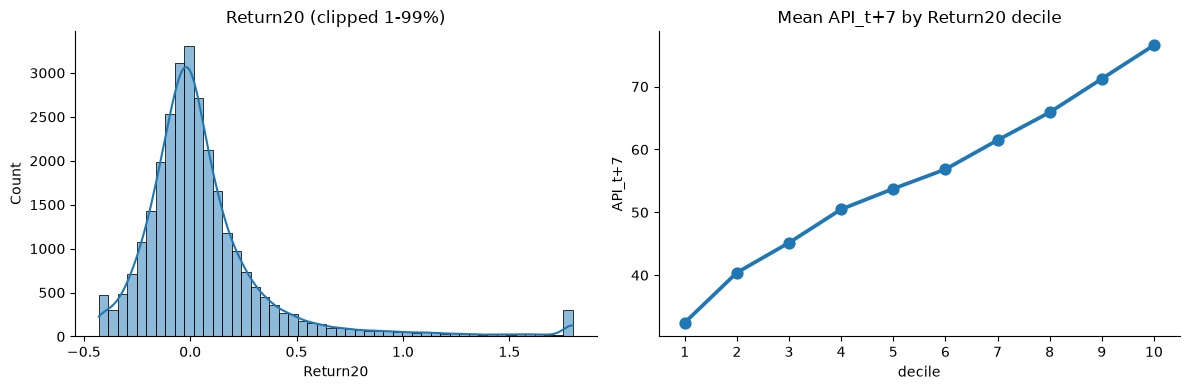

In [206]:
explore(df, ["Return20"])

In [207]:
# Skew and number of negative rows
r = df["Return20"]
print(f"Skew: {r.skew():.1f} | Share negative: {(r < 0).mean():.1%}")

# Mean target by Return20 decile
print("\nMean target by Return20 decile:")
print(df.groupby(pd.qcut(r, 10, labels=False) + 1)[target_name].mean().round(1).to_string())

# Return20 by coin
print("\nReturn20 by coin:")
print(df.groupby("coin")["Return20"].agg(["median", "std", "max"]).round(3))

# Top 5 Return20 values
print("\nTop 5 Return20 values:")
print(df.loc[r.nlargest(5).index, ["coin", "timeOpen", "Return20"]])


Skew: 14.8 | Share negative: 49.8%

Mean target by Return20 decile:
Return20
1     32.5
2     40.4
3     45.2
4     50.5
5     53.8
6     56.8
7     61.5
8     65.9
9     71.2
10    76.6

Return20 by coin:
      median    std     max
coin                       
BTC    0.020  0.178   1.322
DOGE  -0.017  0.615   7.926
ETH    0.009  0.327   3.005
SOL    0.006  0.395   2.774
TRX    0.013  1.227  23.476
XLM   -0.033  0.815  11.871
XMR    0.023  0.364   5.332
XRP   -0.028  0.657  10.320

Top 5 Return20 values:
      coin                  timeOpen   Return20
14061  TRX 2017-12-23 00:00:00+00:00  23.476177
14057  TRX 2017-12-19 00:00:00+00:00  21.650719
14058  TRX 2017-12-20 00:00:00+00:00  20.785711
14059  TRX 2017-12-21 00:00:00+00:00  20.703091
14056  TRX 2017-12-18 00:00:00+00:00  18.319027


In [208]:
feature_1_insights = """
Return20 measures a coin's price change over the past 20 days and drives Return Strength, the largest component of the API (40% weight). Its distribution is centred on zero but heavily right-skewed. Losses cannot exceed −100%, while gains are unbounded, and a few extreme pump episodes in smaller coins (e.g. TRX in late 2017) reach over +2,000%. Because of these outliers, its linear correlation with the target is modest (0.29), but the decile plot shows a strong, steady relationship: higher recent returns lead to a higher API one week later. The effect flattens at the extremes because Return Strength is capped at ±20%. The main issues are the heavy tails, which tree-based models handle well, and the very different return spread across coins. Return20 is also part of the target formula, so some of its predictive power reflects persistence rather than genuine forecasting.
"""

In [209]:
# Do not modify this code
print_tile(size="h3", key='feature_1_insights', value=feature_1_insights)

### C.6 Explore Feature of Interest `TrendStrength`

                 count   mean     std     min      1%     50%     99%     max
TrendStrength  28541.0  0.014  0.1269 -0.4513 -0.2345 -0.0011  0.4927  1.8468

Correlation with target:
 TrendStrength    0.545
Name: API_t+7, dtype: float64


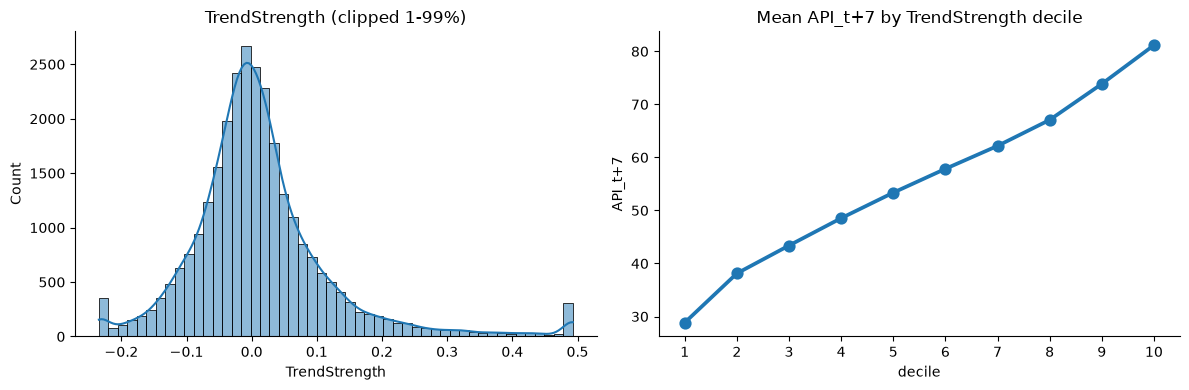

In [210]:
explore(df, ["TrendStrength"])

In [211]:
feature_2_insights = """
TrendStrength compares the 5-day and 20-day moving averages, showing whether short-term prices are above or below the recent trend. It is the strongest single predictor of the target (correlation 0.55), and the decile plot shows a clear, steady rise in the API 7 days ahead as TrendStrength increases. Most values sit close to zero, with a longer tail on the upside during strong rallies. Because the Trend Score is capped at ±10%, very strong trends add no extra information to the target. TrendStrength is also built from the same price history as Return20, so the two overlap. Like Return20, part of its predictive power comes from trends carrying on into the next week rather than genuine forecasting.
"""

In [212]:
# Do not modify this code
print_tile(size="h3", key='feature_2_insights', value=feature_2_insights)

### C.7 Explore Feature of Interest `RelativeVolume` `Volatility20`


                  count    mean     std     min      1%     50%     99%  \
RelativeVolume  28541.0  1.0481  0.6859  0.0515  0.2734  0.9240  3.6895   
Volatility20    28541.0  0.0484  0.0408  0.0049  0.0107  0.0391  0.1861   

                    max  
RelativeVolume  18.1407  
Volatility20     0.8134  

Correlation with target:
 RelativeVolume    0.263
Volatility20      0.034
Name: API_t+7, dtype: float64


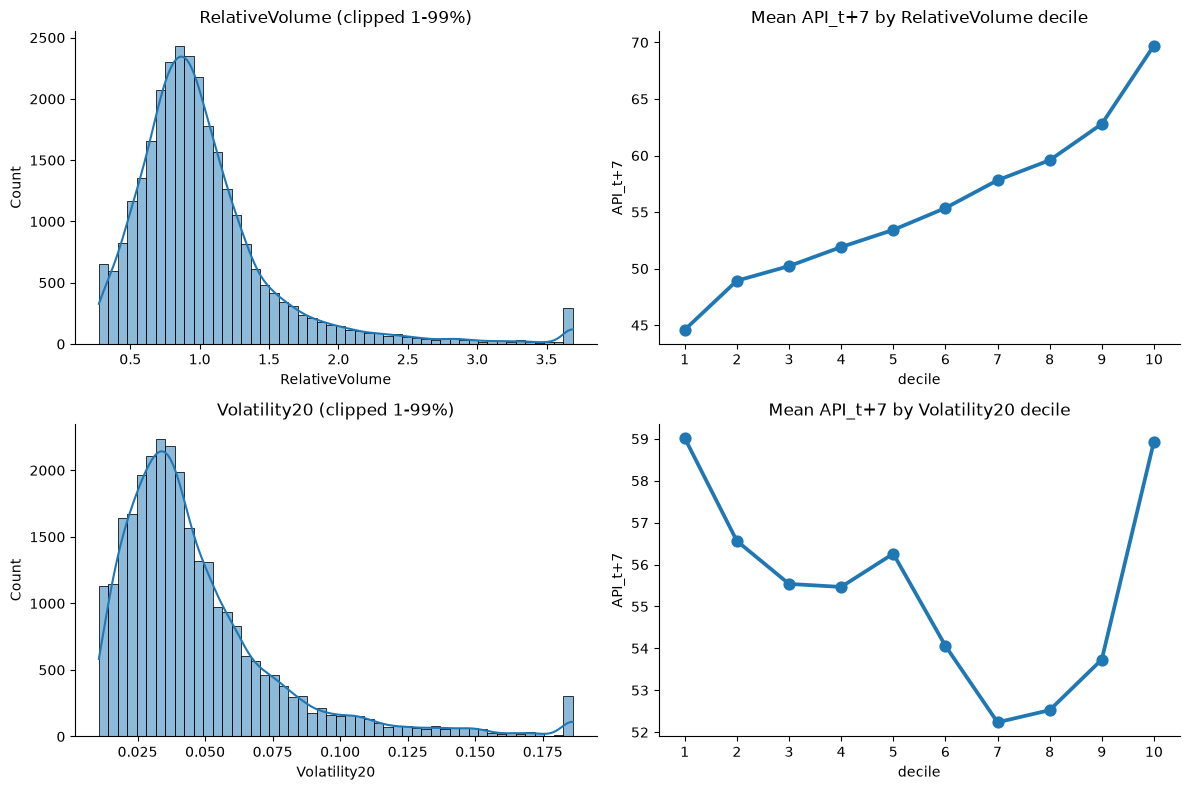

In [213]:
explore(df, ["RelativeVolume", "Volatility20"])

In [214]:
feature_n_insights = """
RelativeVolume compares today's trading volume with its 20-day average, and Volatility20 measures how much daily returns have varied over the past 20 days. Both are right-skewed: most days are close to normal, with occasional sharp spikes during market events. RelativeVolume shows a clear, steady relationship with the target, as unusually high trading activity is followed by a higher API a week later, though the volume score is capped at twice the average. Volatility20 has almost no linear correlation with the target, but its decile plot is U-shaped. The API is highest for both very calm and very volatile coins, because volatility appears both in quiet stable markets and in strong rallies. This non-linear pattern can still be learned by XGBoost. However, Volatility20 carries only 10% of the target's weight, so it is likely to be the least important feature. The main issues for both are heavy right tails and spikes driven by short-lived events, which tree-based models handle well.
"""

In [215]:
# Do not modify this code
print_tile(size="h3", key='feature_n_insights', value=feature_n_insights)

---
## D. Feature Selection



### D.1 Approach "Remove irrelevant columns"


In [216]:
drop_cols = [
    # Duplicate or irrelevant timestamps
    "timeClose", "timeHigh", "timeLow", "timestamp",
    # Constant value
    "name",
    # Mostly missing (>80% for 5 of 8 coins)
    "circulatingSupply",
    # Raw dollar values, not comparable across coins or over time
    "open", "high", "low", "close", "volume", "marketCap",
]

In [217]:
feature_selection_1_insights = """
Before any statistical test, we removed columns that cannot provide useful or valid signal, based on domain knowledge. Twelve columns were dropped. timeClose, timeHigh, timeLow and timestamp either duplicate timeOpen or record intraday times that carry no information for a daily forecast. name holds the same value in every row. circulatingSupply is missing for most rows of five coins. The raw dollar values (open, high, low, close, volume, marketCap) differ in scale by orders of magnitude between coins and drift over time, so they are not comparable across assets. Their useful information is already captured in scale-free features such as returns and ratios.
"""

In [218]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_1_insights', value=feature_selection_1_insights)

### D.2 Approach "Correlation among features"


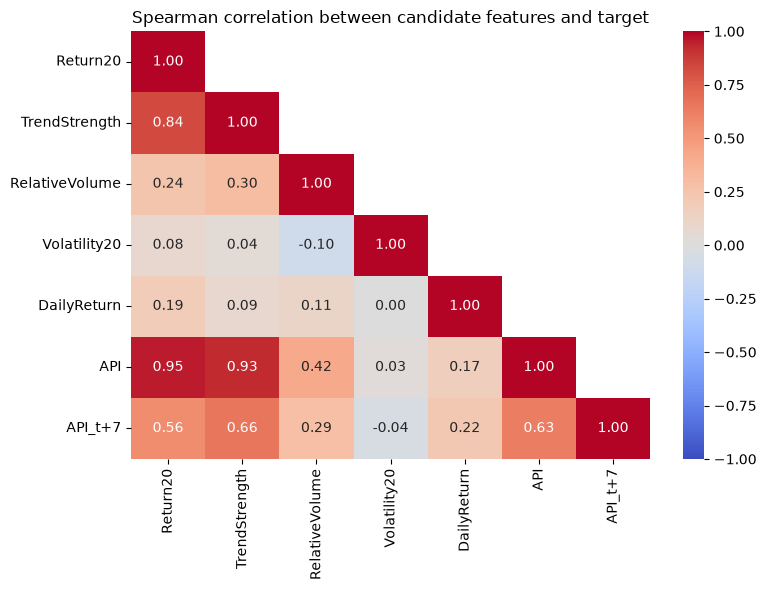

TrendStrength     0.657
API               0.629
Return20          0.558
RelativeVolume    0.286
DailyReturn       0.223
Volatility20     -0.042
Name: API_t+7, dtype: float64
       feature_1      feature_2  spearman
4       Return20            API     0.954
8  TrendStrength            API     0.928
0       Return20  TrendStrength     0.836


In [219]:
candidate_features = ["Return20", "TrendStrength", "RelativeVolume", "Volatility20", "DailyReturn", "API"]

# Spearman
corr = df[candidate_features + [target_name]].corr(method="spearman")

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation between candidate features and target")
plt.tight_layout()
plt.show()

# Correlation of each feature with the target
print(corr[target_name].drop(target_name).sort_values(key=abs, ascending=False).round(3))

# Highly correlated feature pairs
pairs = (corr.loc[candidate_features, candidate_features]
             .where(np.triu(np.ones((len(candidate_features),) * 2, dtype=bool), k=1))
             .stack()
             .rename_axis(["feature_1", "feature_2"])
             .rename("spearman")
             .reset_index())
print(pairs[pairs["spearman"].abs() >= 0.7].sort_values("spearman", key=abs, ascending=False).round(3))


In [220]:
feature_selection_2_insights = """
Spearman correlation measurea how strongly each candidate feature relates to the target, and to detect features that carry overlapping information. Spearman was chosen over Pearson because it is rank-based and not distorted by the heavy tails found in C.5-C.7. TrendStrength, today's API and Return20 show the strongest relationship with API_t+7, while RelativeVolume and DailyReturn are moderate and Volatility20 is close to zero. Three pairs are highly correlated: today's API with Return20 and with TrendStrength, and Return20 with TrendStrength. This is expected, because today's API is built mostly from these two features. All four required features are kept regardless, because overlapping features do not harm tree-based models the way they harm linear models. The overlap does mean their importance will be shared. Volatility20's low correlation is not a reason to drop it, because correlation cannot capture the U-shaped pattern seen in C.7.
"""

In [221]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_2_insights', value=feature_selection_2_insights)

## D.z Final Selection of Features

In [222]:
features_list = ["Return20", "TrendStrength", "RelativeVolume", "Volatility20", "DailyReturn", "API"]

In [223]:
feature_selection_explanations = """
The final model uses six features. Two extra candidates are added. DailyReturn captures very short-term price movement that the 20-day features miss, and it does not overlap strongly with the other inputs. Today's API gives the model the current score as a starting point, so it only needs to learn how the score is likely to change over the next 7 days. Although today's API is highly correlated with Return20 and TrendStrength, this overlap is acceptable for XGBoost, which handles correlated features without becoming unstable. Volatility20 is kept despite its weak linear correlation, because the brief requires it and it shows a non-linear relationship with the target. All irrelevant columns, such as timestamps, constant IDs and raw dollar values, were removed in D.1.
"""

In [224]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_explanations', value=feature_selection_explanations)

---
## E. Data Preparation

### E.1 Data Transformation "No Transformation Needed Here"

In [227]:
data_cleaning_1_explanations = """
No transformation is applied to the selected features. The model is XGBoost, a tree-based algorithm that splits on the order of values rather than their size, so scaling or normalisation would not change its results.
"""

In [228]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_1_explanations', value=data_cleaning_1_explanations)

---
## F. Feature Engineering

### F.1 New Feature "Return5"


In [229]:
df["Return5"] = raw_df.groupby("coin")["close"].pct_change(5, fill_method=None)

print(df["Return5"].describe().round(4))

count    28541.0000
mean         0.0182
std          0.1828
min         -0.5873
25%         -0.0481
50%          0.0003
75%          0.0543
max          8.0989
Name: Return5, dtype: float64


In [230]:
# Correlation with target
print("Spearman with target:", df[["Return5", target_name]].corr(method="spearman").iloc[0, 1].round(3))

Spearman with target: 0.497


In [235]:
features_list = features_list + ["Return5"]
features_list

['Return20',
 'TrendStrength',
 'RelativeVolume',
 'Volatility20',
 'DailyReturn',
 'API',
 'Return5']

In [233]:
feature_engineering_1_explanations = """
Return5 measures a coin's price change over the past 5 days. It fills the gap between DailyReturn, which is noisy day-to-day movement, and Return20, which is the slower monthly trend. It is important because its window is close to the 7-day forecast horizon, so it captures the most recent momentum that is likely to carry into next week's score. It has a strong rank correlation with the target (0.50), close to that of Return20, and like the other return features it is centred near zero with a long upside tail from short pump episodes. The expected impact is a modest improvement in short-term accuracy, which will be confirmed by comparing models with and without Return5 after tuning.
"""

In [234]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_1_explanations', value=feature_engineering_1_explanations)

### F.2 New Feature "Return13"




In [236]:
df["Return13"] = raw_df.groupby("coin")["close"].pct_change(13, fill_method=None)

print(df["Return13"].describe().round(4))


count    28541.0000
mean         0.0545
std          0.4239
min         -0.6643
25%         -0.0825
50%          0.0002
75%          0.0999
max         20.3857
Name: Return13, dtype: float64


In [237]:
# Correlation with target
print("Spearman with target:", df[["Return13", target_name]].corr(method="spearman").iloc[0, 1].round(3))

Spearman with target: 0.717


In [238]:
features_list = features_list + ["Return13"]
features_list

['Return20',
 'TrendStrength',
 'RelativeVolume',
 'Volatility20',
 'DailyReturn',
 'API',
 'Return5',
 'Return13']

In [241]:
feature_engineering_2_explanations = """
Return13 is the price change over the past 13 days. It was designed from the structure of the target. The target uses Return20 measured 7 days ahead, which spans from day t-13 to day t+7, so 13 of those 20 days have already happened at prediction time. Return13 captures exactly this known part, leaving the model to estimate only the remaining 7 days of price movement. This makes it more informative than today's Return20, whose oldest 7 days fall outside next week's window. It has the strongest rank correlation with the target of any feature (0.72), higher than TrendStrength and Return20. It uses only prices up to day t, so it introduces no data leakage. As one of Student A's own features computed from closing prices, it adds no dependency on other APIs. Like the other return features, it is centred near zero with a long upside tail. The expected impact is a clear reduction in prediction error, which will be confirmed by comparing models with and without Return13 after tuning.
"""

In [242]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_2_explanations', value=feature_engineering_2_explanations)

---
## G. Data Preparation for Modeling

### G.1 Split Datasets

In [243]:
HORIZON = 7
VAL_START  = pd.Timestamp("2023-01-01", tz="UTC")
TEST_START = pd.Timestamp("2024-01-01", tz="UTC")
gap = pd.Timedelta(days=HORIZON)

t = df["timeOpen"]
train_df = df[t <  VAL_START - gap]
val_df   = df[(t >= VAL_START) & (t < TEST_START - gap)]
test_df  = df[t >= TEST_START]

X_train, y_train = train_df[features_list], train_df[target_name]
X_val,   y_val   = val_df[features_list],   val_df[target_name]
X_test,  y_test  = test_df[features_list],  test_df[target_name]

for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s} {len(part):6d} rows | {part['timeOpen'].min().date()} → {part['timeOpen'].max().date()}")
print(test_df.groupby("coin").size().to_dict())

train  20131 rows | 2014-12-17 → 2022-12-24
val     2513 rows | 2023-01-01 → 2023-12-24
test    5792 rows | 2024-01-01 → 2025-12-24
{'BTC': 724, 'DOGE': 724, 'ETH': 724, 'SOL': 724, 'TRX': 724, 'XLM': 724, 'XMR': 724, 'XRP': 724}


In [246]:
data_splitting_explanations = """
The data is split chronologically. The training set covers December 2014 to December 2022 (20,131 rows), spanning several full market cycles, including the 2017 boom, the 2018 crash, the 2020-21 bull run and the 2022 bear market. The validation set covers 2023 (2,513 rows) and is used for Optuna tuning and model selection. The test set covers 2024-2025 (5,792 rows, balanced across all 8 coins) and is used only once for the final evaluation. A 7-day gap is left between consecutive sets, because each label uses prices up to 7 days ahead. Without the gap, the last training labels would be built from validation-period prices, causing leakage. One limitation is that XLM has almost no data in the validation year due to its missing 2023 file, so tuning is mainly based on the other seven coins. After tuning, the final model will be retrained on the combined training and validation data before being scored on the test set.
"""

In [247]:
# Do not modify this code
print_tile(size="h3", key='data_splitting_explanations', value=data_splitting_explanations)

### G.2 Data Transformation "No Transformation"

In [248]:
data_transformation_1_explanations = """
No transformation was conducted here.
"""

In [249]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_1_explanations', value=data_transformation_1_explanations)

---
## H. Save Datasets


In [250]:
data_final_path = '../data/processed'

In [251]:
# Do not modify this code
# Save training set
try:
  X_train.to_csv(f'{data_final_path}/X_train.csv', index=False)
  y_train.to_csv(f'{data_final_path}/y_train.csv', index=False)

  X_val.to_csv(f'{data_final_path}/X_val.csv', index=False)
  y_val.to_csv(f'{data_final_path}/y_val.csv', index=False)

  X_test.to_csv(f'{data_final_path}/X_test.csv', index=False)
  y_test.to_csv(f'{data_final_path}/y_test.csv', index=False)
except Exception as e:
  print(e)

---
## I. Selection of Performance Metrics

> Provide some explanations on why you believe the performance metrics you chose is appropriate


In [261]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
print('The main metric: MAE')
print('The secondary metric: RMSE')

The main metric: MAE
The secondary metric: RMSE


In [255]:
performance_metrics_explanations = """
Mean Absolute Error (MAE) is the primary metric because it is measured in the same units as the target, so it is easy for investors and stakeholders to interpret. MAE also treats all errors equally, so a few extreme weeks of crypto volatility do not dominate the evaluation and it reflects typical accuracy. Root Mean Squared Error (RMSE) is used as a secondary metric because it penalises large errors more heavily. A large gap between RMSE and MAE would show that the model occasionally makes big misses, which matters for users who may act on a score that is far from reality.
"""

In [256]:
# Do not modify this code
print_tile(size="h3", key='performance_metrics_explanations', value=performance_metrics_explanations)

## J. Train Machine Learning Model

### J.1 Import Algorithm

> Provide some explanations on why you believe this algorithm is a good fit


In [257]:
from xgboost import XGBRegressor

In [259]:
algorithm_selection_explanations = """
XGBoost is a gradient-boosted tree model, which builds many small decision trees that each correct the errors of the previous ones. It is therefore good at capturing non-linear relationships and interactions, such as the capped components of the API formula and the U-shaped pattern of Volatility20 seen in C.7. Because trees split on the order of values rather than their size, XGBoost is not affected by the heavy-tailed return features, and it needs no scaling or log transforms. It also tolerates highly correlated inputs, such as Return20, TrendStrength and today's API, without becoming unstable. Its native handling of missing values is important for deployment, because if a teammate's API is unavailable, the missing feature can be passed as NaN and the model still produces a prediction. Finally, XGBoost is fast to train, works well with Optuna for hyperparameter tuning, and provides built-in feature importance, which the Streamlit page must display.
"""

In [260]:
# Do not modify this code
print_tile(size="h3", key='algorithm_selection_explanations', value=algorithm_selection_explanations)

### J.2 Set Hyperparameters

> Provide some explanations on why you believe this algorithm is a good fit


In [265]:
import optuna

In [269]:
SEED = 42
N_TRIALS = 51

def objective(trial):
    params = {
        "n_estimators":     2000,
        "learning_rate":    trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "max_depth":        trial.suggest_int("max_depth", 3, 8),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 50, log=True),
        "subsample":        trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "gamma":            trial.suggest_float("gamma", 1e-3, 10, log=True),
        "reg_alpha":        trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "reg_lambda":       trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    }
    model = XGBRegressor(**params, objective="reg:squarederror", eval_metric="mae",
                         early_stopping_rounds=50, random_state=SEED, n_jobs=-1)
    model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    trial.set_user_attr("best_iteration", model.best_iteration)
    return mean_absolute_error(y_val, model.predict(X_val))

In [262]:
hyperparameters_selection_explanations = """
Crypto prices are noisy, and an untuned XGBoost can easily overfit, memorising past market moves that do not repeat. The tuned hyperparameters control this trade-off in three groups. learning_rate and max_depth set how quickly the model learns and how complex each tree can be. They interact, so they are searched together. The number of trees is not tuned directly, because early stopping on validation MAE selects it automatically for each trial. min_child_weight, gamma, reg_alpha and reg_lambda penalise splits and leaf values that the data does not strongly support, which is the main defence against fitting noise. subsample and colsample_bytree train each tree on a random share of rows and features, so consecutive trees do not all learn the same pattern. This is important here because several features, such as Return20, Return13 and today's API, are highly correlated. Learning rate, min_child_weight and the regularisation terms are searched on a log scale, because their useful values span several orders of magnitude. Optuna's TPE sampler with a fixed seed makes the search reproducible, and it minimises MAE on the 2023 validation set so that tuning targets the same metric used for evaluation.
"""

In [263]:
# Do not modify this code
print_tile(size="h3", key='hyperparameters_selection_explanations', value=hyperparameters_selection_explanations)

### J.3 Fit Model

In [270]:
optuna.logging.set_verbosity(optuna.logging.INFO)
study = optuna.create_study(direction="minimize", study_name="api_xgb",
                            sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

best_params = study.best_params
best_n_estimators = study.best_trial.user_attrs["best_iteration"] + 1
print(f"Best validation MAE: {study.best_value:.3f}")
print(f"Best n_estimators:   {best_n_estimators}")
print("Best params:", best_params)

[I 2026-10-23 21:50:06,764] A new study created in memory with name: api_xgb
Best trial: 0. Best value: 9.9406:   2%|▏         | 1/51 [00:00<00:27,  1.80it/s]

[I 2026-10-23 21:50:07,322] Trial 0 finished with value: 9.940603484122303 and parameters: {'learning_rate': 0.030710573677773714, 'max_depth': 8, 'min_child_weight': 17.524101118128137, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.5780093202212182, 'gamma': 0.004207053950287938, 'reg_alpha': 0.0017073967431528124, 'reg_lambda': 2.915443189153755}. Best is trial 0 with value: 9.940603484122303.


Best trial: 0. Best value: 9.9406:   4%|▍         | 2/51 [00:00<00:20,  2.42it/s]

[I 2026-10-23 21:50:07,636] Trial 1 finished with value: 9.96966849089675 and parameters: {'learning_rate': 0.06054365855469249, 'max_depth': 7, 'min_child_weight': 1.0838581269344745, 'subsample': 0.9849549260809971, 'colsample_bytree': 0.9162213204002109, 'gamma': 0.0070689749506246055, 'reg_alpha': 0.005337032762603957, 'reg_lambda': 0.00541524411940254}. Best is trial 0 with value: 9.940603484122303.


Best trial: 2. Best value: 9.8514:   6%|▌         | 3/51 [00:01<00:23,  2.00it/s]

...

[I 2026-10-23 21:50:27,035] Trial 48 finished with value: 9.815668523754843 and parameters: {'learning_rate': 0.03810895030701364, 'max_depth': 3, 'min_child_weight': 37.428081090899354, 'subsample': 0.5943233707730758, 'colsample_bytree': 0.9276170701657989, 'gamma': 0.003747387275392816, 'reg_alpha': 0.8472095709273857, 'reg_lambda': 2.104577485758238}. Best is trial 34 with value: 9.790083067378724.


Best trial: 34. Best value: 9.79008:  98%|█████████▊| 50/51 [00:20<00:00,  3.19it/s]

[I 2026-10-23 21:50:27,452] Trial 49 finished with value: 9.81999484761651 and parameters: {'learning_rate': 0.019396798600525164, 'max_depth': 3, 'min_child_weight': 3.5625712816577035, 'subsample': 0.837091212067197, 'colsample_bytree': 0.8956167350813997, 'gamma': 0.015246732937309819, 'reg_alpha': 1.5393002330044623, 'reg_lambda': 0.33325584619660337}. Best is trial 34 with value: 9.790083067378724.


Best trial: 34. Best value: 9.79008: 100%|██████████| 51/51 [00:21<00:00,  2.39it/s]

[I 2026-10-23 21:50:28,082] Trial 50 finished with value: 9.813709965845876 and parameters: {'learning_rate': 0.014364748466395273, 'max_depth': 4, 'min_child_weight': 25.690251716606227, 'subsample': 0.5306393368717526, 'colsample_bytree': 0.9690634132749896, 'gamma': 0.0022947441220131063, 'reg_alpha': 2.516486497570993, 'reg_lambda': 0.04189858966769292}. Best is trial 34 with value: 9.790083067378724.
Best validation MAE: 9.790
Best n_estimators:   149
Best params: {'learning_rate': 0.029199922572041178, 'max_depth': 3, 'min_child_weight': 33.16014684053048, 'subsample': 0.5252834778110732, 'colsample_bytree': 0.8194653788060381, 'gamma': 0.0010512980438210408, 'reg_alpha': 0.9231859498607357, 'reg_lambda': 6.538341334689918}


### J.4 Model Technical Performance

> Provide some explanations on model performance


In [272]:
# Baseline
def evaluate(y_true, y_pred, name):
    return {"model": name,
            "MAE":  round(mean_absolute_error(y_true, y_pred), 3),
            "RMSE": round(root_mean_squared_error(y_true, y_pred), 3)}

train_mean = y_train.mean()

baseline_results = []
for split, part, y in [("val", val_df, y_val), ("test", test_df, y_test)]:
    # Today's API
    baseline_results.append({"split": split, **evaluate(y, part["API"], "API today")})
    # Mean train
    baseline_results.append({"split": split, **evaluate(y, [train_mean] * len(y), "Mean of train")})

baseline_df = pd.DataFrame(baseline_results)
baseline_df

,split,model,MAE,RMSE
0,val,API today,12.054,16.177
1,val,Mean of train,14.741,18.660
2,test,API today,14.110,18.469
3,test,Mean of train,17.267,21.025


In [ ]:
# Retrain the model with the best hyperparameters
model = XGBRegressor(
    **best_params,
    n_estimators=best_n_estimators,
    objective="reg:squarederror",
    random_state=SEED,
    n_jobs=-1,
)
model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8194653788060381, device=None,
             early_stopping_rounds=None, enable_categorical=True,
             eval_metric=None, feature_types=None, feature_weights=None,
             gamma=0.0010512980438210408, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.029199922572041178, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=3, max_leaves=None,
             min_child_weight=33.16014684053048, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=149,
             n_jobs=-1, num_parallel_tree=None, ...)

In [277]:
# Evaluate on train, val and test
model_results = []
for split, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    model_results.append({"split": split, **evaluate(y, model.predict(X), "XGBoost (tuned)")})

pd.DataFrame(model_results)

,split,model,MAE,RMSE
0,train,XGBoost (tuned),12.726,16.614
1,val,XGBoost (tuned),9.790,13.142
2,test,XGBoost (tuned),11.288,14.655


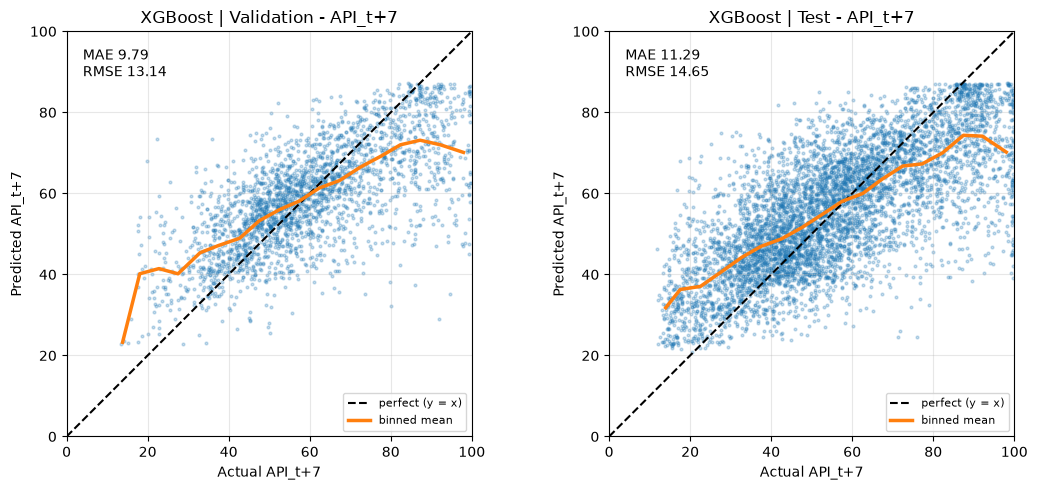

In [279]:
def plot_pred_vs_actual(model, splits, n_bins=20, lims=(0, 100)):
    """Predicted vs actual scatter with y = x line and binned mean, one panel per split."""
    fig, axes = plt.subplots(1, len(splits), figsize=(5.5 * len(splits), 5), squeeze=False)
    for ax, (name, X, y) in zip(axes[0], splits):
        pred = model.predict(X)
        mae  = mean_absolute_error(y, pred)
        rmse = root_mean_squared_error(y, pred)

        ax.scatter(y, pred, s=4, alpha=0.25, color="tab:blue")
        ax.plot(lims, lims, "k--", lw=1.5, label="perfect (y = x)")

        bins = pd.cut(y, np.linspace(*lims, n_bins + 1))
        binned = pd.DataFrame({"actual": y.values, "pred": pred}).groupby(bins.values, observed=True).mean()
        ax.plot(binned["actual"], binned["pred"], color="tab:orange", lw=2.5, label="binned mean")

        ax.text(0.04, 0.96, f"MAE {mae:.2f}\nRMSE {rmse:.2f}", transform=ax.transAxes, va="top")
        ax.set(xlim=lims, ylim=lims, aspect="equal",
               title=f"XGBoost | {name} - {target_name}",
               xlabel=f"Actual {target_name}", ylabel=f"Predicted {target_name}")
        ax.grid(alpha=0.3)
        ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()

plot_pred_vs_actual(model, [("Validation", X_val, y_val), ("Test", X_test, y_test)])


In [286]:
# Feature Importance
from sklearn.inspection import permutation_importance

perm = permutation_importance(model, X_test, y_test, scoring="neg_mean_absolute_error", n_repeats=10, random_state=SEED, n_jobs=-1)
perm_mae = pd.Series(perm.importances_mean, index=features_list).clip(lower=0)
perm_share = perm_mae / perm_mae.sum()   

In [287]:
# Save the model and its metadata
import joblib
import json
from pathlib import Path

MODEL_DIR = Path("../models")

# Save the model
joblib.dump(model, MODEL_DIR / "studenta_xgb.joblib")

# Save the metadata
test_row = next(r for r in model_results if r["split"] == "test")
metadata = {
    "target": "Asset Performance Index",
    "target_description": (
        "0-100 score of a cryptocurrency's performance 7 days ahead: "
        "100 x (0.40 x Return Strength + 0.30 x Trend Strength Score "
        "+ 0.20 x Relative Volume Score + 0.10 x Price Stability)."
    ),
    "algorithm": "XGBoost Regressor",
    "forecast_horizon": HORIZON,
    "features": features_list,
    "feature_importance": {f: round(float(v), 4) for f, v in perm_share.items()},
    "feature_importance_method": "permutation importance on the 2024-2025 test set (MAE)",
    "metrics": {"test_MAE": test_row["MAE"], "test_RMSE": test_row["RMSE"]},
    "hyperparameters": {**best_params, "n_estimators": best_n_estimators},
    "trained_on": f"{train_df['timeOpen'].min().date()} to {train_df['timeOpen'].max().date()}",
}

with open(MODEL_DIR / "api_xgb_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

In [282]:
model_performance_explanations = """
The tuned XGBoost model clearly outperforms both baselines on unseen data. On the 2024-2025 test set, it achieves an MAE of 11.29 and an RMSE of 14.66, compared with 14.11 and 18.47 for the naive "next week = today" baseline and 17.27 and 21.03 for the training mean. This is a 20% reduction in MAE against the naive baseline. Validation performance is similar (MAE 9.79 vs 12.05, a 19% improvement), although 2023 was an unusually calm year, so the test score is the more realistic estimate. The model shows no sign of overfitting: its training MAE (12.73) is actually higher than its validation and test MAE, because the training period includes the very volatile 2015-2018 markets. Optuna also selected shallow trees (depth 3) with strong regularisation. The predicted-versus-actual plots show that the model tracks the target well in the middle range (about 40-70), but its predictions are pulled toward the average at the extremes. Weak weeks are over-predicted, strong weeks are under-predicted, and predictions rarely go below 20 or above 85. This is typical for a noisy 7-day-ahead forecast and means the model is cautious exactly where investors care most, so the score should be read as a direction-of-travel signal rather than a precise value at the extremes.
"""

In [283]:
# Do not modify this code
print_tile(size="h3", key='model_performance_explanations', value=model_performance_explanations)

### J.5 Business Impact from Current Model Performance

> Provide some analysis on the model impacts from the business point of view


In [284]:
business_impacts_explanations = """
The model meets the business objective. On unseen 2024-2025 data it reduces forecast error by 20% compared with simply reusing today's score, which exceeds the 10% success threshold, so the hypothesis is confirmed. In practice, investors get a more reliable 7-day outlook for comparing coins than they would by reading the current score alone. However, a typical error of about 11 points on a 0-100 scale means the score is best used as a directional signal, such as "likely to strengthen" or "likely to weaken", rather than a precise value. Not all errors carry the same cost. The most harmful is overestimating a coin that is about to weaken: the model tends to predict weak weeks as around 35-45 instead of 15-25, so it can understate a coming downturn, and a user who buys on that signal may take a real financial loss. Underestimating strong weeks is less costly, since the main impact is a missed opportunity rather than a direct loss. However, because predictions rarely exceed 85, the platform will seldom flag the strongest rallies. Errors also differ by asset: forecasts for volatile coins such as DOGE and SOL are less accurate than for BTC or TRX, so users of those pages face higher risk. To limit these impacts, the Streamlit page should show the score with its typical error range and feature drivers. It should flag low-confidence situations and state clearly that the score is decision support, not financial advice, which protects both users and the platform's credibility.
"""

In [285]:
# Do not modify this code
print_tile(size="h3", key='business_impacts_explanations', value=business_impacts_explanations)

## H. Project Outcomes

In [288]:
experiment_outcome = "Hypothesis Confirmed"

In [289]:
# Do not modify this code
print_tile(size="h2", key='experiment_outcomes_explanations', value=experiment_outcome)

In [292]:
experiment_results_explanations = """
The experiment confirmed the hypothesis. The tuned XGBoost model reduced test MAE by 20% against the naive "next week = today" baseline (11.29 vs 14.11), beat the baseline for all 8 coins, and showed no overfitting.
Key insights: (1) The target is highly persistent, so the naive baseline is the correct benchmark, and beating the training mean alone would have overstated the model's value. (2) The largest gain came from analysing the target formula rather than tuning. Return13 captures the 13 days of next week's 20-day window that are already known, and it dominates permutation importance. (3) The required features overlap heavily: Return20 adds almost nothing once Return13 and today's API are present, and Volatility20 contributes little because of its 10% weight in the formula. (4) A single pooled model on scale-free features performed as well as per-coin models and better for short-history coins such as SOL. (5) 2023 was an unusually easy year, so validation scores were optimistic. (6) Predictions are pulled toward the average at the extremes, which matters most for investors.
The approach is not a dead end, but further hyperparameter tuning has reached diminishing returns: walk-forward and single-split tuning gave the same test MAE. Future gains are more likely to come from better features and from making the model robust in production.
Next steps, ranked by expected value: (1) Fault-tolerant training. Randomly blank teammates' features during training so the model stays accurate when a peer API is down. This gives high gain in production reliability with no change to normal accuracy, and is essential for deployment. (2) More "known-window" features, such as the known part of next week's MA20 and volume average. This could give a moderate accuracy gain (perhaps 1-3% MAE), following the same reasoning as Return13. (3) Quantile models (10th and 90th percentile) to show a prediction range. This adds no accuracy but improves user trust and addresses the problem of predictions being pulled toward the middle. (4) Re-downloading the missing XLM 2023 data, a small gain in data quality. (5) Monitoring for drift between CoinMarketCap training data and Kraken production data, with periodic retraining. This protects accuracy over time.
Deployment: copy api_xgb.json and its metadata into the Student A FastAPI repo. Compute features with the same shared functions used in training, from completed Kraken daily candles.
"""


In [293]:
# Do not modify this code
print_tile(size="h2", key='experiment_results_explanations', value=experiment_results_explanations)